<div style="background:linear-gradient(120deg,#081327,#283564);padding:36px;border-radius:18px;color:#f4f8ff;border-top:7px solid #36dec2">
<p style="color:#36dec2;letter-spacing:3px">THE MARKET DATA LAB · VOO</p>
<h1 style="font-size:38px;color:white">From historical prices<br>to honest forecasts</h1>
<p style="font-size:19px;color:#c6d6f0">Vanguard S&amp;P 500 ETF · 2010–2026 · EDA &amp; Machine Learning</p>
<p><b>Muhammad Ibrahim Shahrukh</b> | Prepared September 29, 2026</p></div>

**Research question:** What do VOO's supplied daily prices reveal about returns, risk and volume—and can a machine-learning model improve on a simple baseline over the remaining 2026 trading sessions?

**What you will learn:** audit an OHLCV dataset, separate price levels from returns, examine drawdowns and changing volatility, build strictly time-ordered forecasting experiments, and interpret uncertainty without promises.

> VOO is an exchange-traded fund that tracks the S&P 500, not the index itself. The last observation is September 28, 2026. All projections use only this uploaded snapshot; no live prices or current macroeconomic inputs are fetched. The source adjustment settings are unknown. Returns below refer to the supplied close series and are **not asserted to be investor total returns**.

**Reading map:** 01 Setup → 02 Audit → 03 Market dashboard → 04 Returns & risk → 05 Calendar patterns → 06 Dependence → 07 Features → 08 Validation → 09 Test → 10 Explainability → 11 Forecast → 12 Findings & sources.

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">01</b><h2 style="margin:8px 0;color:#eef5ff">A reproducible, offline-first workspace</h2></div>

Attach `voo_daily_clean.csv` with Kaggle **Add Input**, or keep it beside this notebook locally. Use Python 3.11+ and the included requirements file. No package installation or data download is performed by the notebook. Interactive Plotly figures and static Matplotlib companions are both saved in the outputs, so the main visuals remain visible in viewers that block JavaScript.

In [1]:
from pathlib import Path
import os, json, hashlib, platform, importlib.metadata, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from IPython.display import display, HTML, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.stattools import adfuller, acf
import exchange_calendars as xcals

SEED = 42
DATA_PATH = None  # Optional: Path('/kaggle/input/your-dataset/voo_daily_clean.csv')
OUTPUT = Path('/kaggle/working/voo_outputs') if Path('/kaggle/working').exists() else Path('outputs')
OUTPUT.mkdir(exist_ok=True, parents=True)
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(exist_ok=True)
COLORS = ['#36dec2','#8ab9ff','#c291ff','#ffbf69','#ff7285','#a0e6ff']
px.defaults.template = 'plotly_dark'
px.defaults.color_discrete_sequence = COLORS
sns.set_theme(style='darkgrid', palette=COLORS)
plt.rcParams.update({'figure.facecolor':'#0d1930','axes.facecolor':'#12213c',
    'axes.edgecolor':'#677896','axes.labelcolor':'#e5edff','text.color':'#e5edff',
    'xtick.color':'#c5d0e6','ytick.color':'#c5d0e6','grid.color':'#33435d',
    'font.size':10,'savefig.facecolor':'#0d1930'})
_first_plot = True
def show_plot(fig, name):
    # Both MIME types support notebooks; self-contained HTML also works offline.
    global _first_plot
    fig.update_layout(paper_bgcolor='#0d1930', plot_bgcolor='#12213c',
                      font=dict(family='Arial', color='#e5edff'), margin=dict(t=75,b=55))
    html = fig.to_html(full_html=False, include_plotlyjs=True if _first_plot else False)
    display({'application/vnd.plotly.v1+json':json.loads(fig.to_json()), 'text/html':html}, raw=True)
    _first_plot = False
    fig.write_html(FIGURES / f'{name}.html', include_plotlyjs=True)

def static_done(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=135, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def note(title, body, color='#36dec2'):
    display(HTML(f'<div style="border-left:5px solid {color};background:#12213c;color:#eef5ff;padding:16px;margin:12px 0;border-radius:8px"><b style="color:{color}">{title}</b><br>{body}</div>'))

versions = {p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','plotly','matplotlib','seaborn','statsmodels','exchange-calendars']}
versions['python'] = platform.python_version()
display(pd.Series(versions, name='version').to_frame())

,version
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.8.0
plotly,7.1.0
matplotlib,3.10.8
seaborn,0.13.2
statsmodels,0.15.0
exchange-calendars,4.13.2
python,3.12.14


<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">02</b><h2 style="margin:8px 0;color:#eef5ff">Trust the rows before trusting a chart</h2></div>

The original CSV has a Price header, a ticker metadata row, and a Date metadata row. The supplied cleaner removes only those two metadata rows, uses lowercase names, adds an explicit ticker, sorts dates, and rounds prices to six decimal places. It validates numeric types and OHLC relationships, preserves real extremes, and does not impute prices. Exact duplicates would be removed; conflicting dates cause an error. The original snapshot, cleaner and SHA-256 hashes are included in the package.

In [2]:
if DATA_PATH is None:
    candidates = [p.resolve() for p in [Path('voo_daily_clean.csv'), Path('data/voo_daily_clean.csv')] if p.is_file()]
    if not candidates and Path('/kaggle/input').exists():
        candidates = [p.resolve() for p in Path('/kaggle/input').rglob('voo_daily_clean.csv')]
    candidates = sorted(set(candidates))
    if len(candidates) != 1:
        raise ValueError(f'Expected exactly one clean CSV, found {len(candidates)}. Set DATA_PATH explicitly.')
    DATA_PATH = candidates[0]
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
assert df.columns.tolist() == ['date','ticker','open','high','low','close','volume']
assert df.date.is_unique and df.date.is_monotonic_increasing
assert df.ticker.eq('VOO').all() and df.notna().all().all()
assert np.isfinite(df.select_dtypes('number')).all().all()
assert (df[['open','high','low','close']] > 0).all().all()
assert ((df.volume >= 0) & (df.volume % 1 == 0)).all()
assert (df.high >= df[['open','close','low']].max(axis=1) - 1e-6).all()
assert (df.low <= df[['open','close','high']].min(axis=1) + 1e-6).all()
calendar = xcals.get_calendar('XNYS', start=df.date.min(), end='2026-12-31')
expected = calendar.sessions_in_range(df.date.min(), df.date.max()).tz_localize(None)
missing_sessions = expected.difference(pd.DatetimeIndex(df.date))
unexpected_sessions = pd.DatetimeIndex(df.date).difference(expected)
audit = pd.DataFrame({'check':['Rows','Duplicate dates','Missing cells','Missing exchange sessions',
                              'Unexpected session dates','Zero volume rows'],
                      'value':[len(df),df.date.duplicated().sum(),df.isna().sum().sum(),
                               len(missing_sessions),len(unexpected_sessions),(df.volume==0).sum()]})
display(audit)
assert len(missing_sessions) == 0 and len(unexpected_sessions) == 0, 'Review calendar gaps before forecasting.'
display(df.head(4))
display(df.tail(4))
display(df[['open','high','low','close','volume']].describe().round(3))
audit.to_csv(OUTPUT/'quality_checks.csv',index=False)
note('Price basis', 'OHLC values are preserved on the source scale. The export lacks Adj Close, dividends, splits, download timestamp and adjustment flags. Do not infer a verified raw-price or total-return series from the column names alone.', '#ffbf69')

,check,value
0,Rows,4037
1,Duplicate dates,0
2,Missing cells,0
3,Missing exchange sessions,0
4,Unexpected session dates,0
5,Zero volume rows,0


,date,ticker,open,high,low,close,volume
0,2010-09-09,VOO,77.003908,77.003908,75.982197,76.117424,26500
1,2010-09-10,VOO,76.387842,76.523069,76.102367,76.462967,8600
2,2010-09-13,VOO,77.349444,77.484670,77.003866,77.424568,33750
3,2010-09-14,VOO,77.259314,77.740124,76.913736,77.409569,59400


,date,ticker,open,high,low,close,volume
4033,2026-09-23,VOO,710.313551,710.552926,704.548346,705.785156,13808900
4034,2026-09-24,VOO,702.264264,706.772691,701.546079,705.176758,9419700
4035,2026-09-25,VOO,706.623031,709.824821,704.368818,708.966980,5462300
4036,2026-09-28,VOO,706.289978,707.330017,701.969971,703.609985,8539400


,open,high,low,close,volume
count,4037.000,4037.000,4037.000,4037.000,4.037000e+03
mean,270.497,271.870,268.983,270.535,3.348616e+06
std,162.050,162.835,161.187,162.069,3.342529e+06
min,76.358,76.523,75.665,76.117,8.600000e+03
25%,146.551,147.497,145.656,146.505,1.194600e+06
50%,221.623,222.957,220.350,221.714,2.618300e+06
75%,371.208,373.227,368.064,371.422,4.522300e+06
max,713.795,714.553,710.972,713.116,3.706240e+07


<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">03</b><h2 style="margin:8px 0;color:#eef5ff">The market at a glance</h2></div>

Start with context: the full close-price path, volume, recent candlesticks and rolling averages. Moving averages summarize history; crossovers are not evaluated trading rules here. Volume is in shares, and all price values are USD on the supplied source scale.

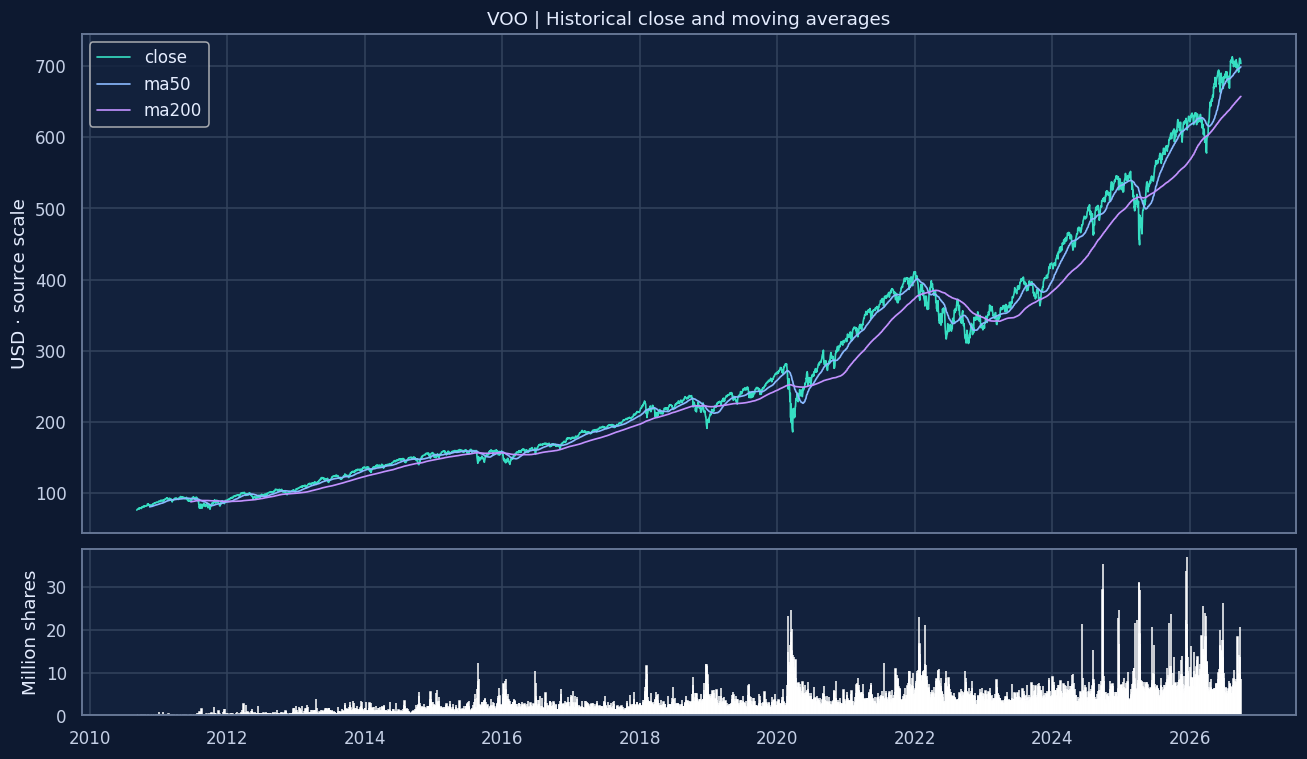

In [3]:
e = df.copy()
e['return'] = e.close.pct_change(fill_method=None)
e['log_return'] = np.log(e.close).diff()
e['drawdown'] = e.close / e.close.cummax() - 1
e['vol21'] = e.log_return.rolling(21).std() * np.sqrt(252)
e['vol63'] = e.log_return.rolling(63).std() * np.sqrt(252)
e['ma50'] = e.close.rolling(50).mean()
e['ma200'] = e.close.rolling(200).mean()
e['range_pct'] = (e.high-e.low) / e.close * 100
years = (e.date.iloc[-1] - e.date.iloc[0]).days / 365.25
summary = {'observations':len(e),'first_date':str(e.date.iloc[0].date()),'last_date':str(e.date.iloc[-1].date()),
           'latest_close':float(e.close.iloc[-1]),'series_change_pct':float((e.close.iloc[-1]/e.close.iloc[0]-1)*100),
           'series_cagr_pct':float(((e.close.iloc[-1]/e.close.iloc[0])**(1/years)-1)*100),
           'annualized_volatility_pct':float(e.log_return.std()*np.sqrt(252)*100),
           'maximum_drawdown_pct':float(e.drawdown.min()*100)}
cards = [('OBSERVATIONS',f'{len(e):,}'),('LATEST CLOSE',f'${e.close.iloc[-1]:,.2f}'),
         ('ANNUALIZED VOL',f'{summary["annualized_volatility_pct"]:.1f}%'),
         ('MAX DRAWDOWN',f'{summary["maximum_drawdown_pct"]:.1f}%')]
display(HTML('<div style="display:flex;flex-wrap:wrap;gap:12px">'+''.join(
    f'<div style="background:#172747;color:white;border-top:4px solid {COLORS[i]};padding:20px;min-width:150px;border-radius:10px"><span style="color:{COLORS[i]}">{k}</span><h2 style="color:white">{v}</h2></div>' for i,(k,v) in enumerate(cards))+'</div>'))
fig = make_subplots(rows=2,cols=1,shared_xaxes=True,row_heights=[.73,.27],vertical_spacing=.08)
for col,color in [('close',COLORS[0]),('ma50',COLORS[1]),('ma200',COLORS[2])]:
    fig.add_trace(go.Scatter(x=e.date,y=e[col],name=col,line=dict(color=color,width=1.5)),row=1,col=1)
fig.add_trace(go.Bar(x=e.date,y=e.volume/1e6,name='Volume (millions)',marker_color=COLORS[1]),row=2,col=1)
fig.update_layout(title='VOO | Sixteen years of price history',height=680)
fig.update_yaxes(title_text='USD · source scale',row=1,col=1)
fig.update_yaxes(title_text='Million shares',row=2,col=1)
show_plot(fig,'01_history')
f,ax=plt.subplots(2,1,figsize=(12,7),sharex=True,gridspec_kw={'height_ratios':[3,1]})
for col in ['close','ma50','ma200']: ax[0].plot(e.date,e[col],label=col,lw=1.1)
ax[0].set(title='VOO | Historical close and moving averages',ylabel='USD · source scale');ax[0].legend()
ax[1].bar(e.date,e.volume/1e6,color=COLORS[1]);ax[1].set_ylabel('Million shares')
static_done(f,'01_history')

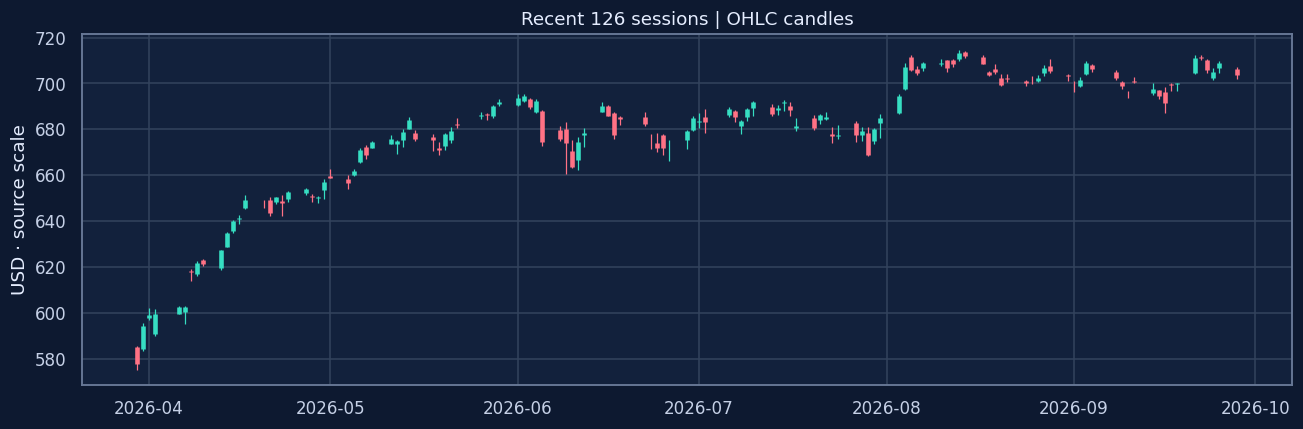

In [4]:
recent=e.tail(126)
fig=go.Figure(go.Candlestick(x=recent.date,open=recent.open,high=recent.high,low=recent.low,close=recent.close,
                            increasing_line_color=COLORS[0],decreasing_line_color=COLORS[4],name='OHLC'))
fig.update_layout(title='Recent 126 sessions | Candlesticks',height=500,xaxis_rangeslider_visible=False,yaxis_title='USD · source scale')
show_plot(fig,'02_candles')
f,ax=plt.subplots(figsize=(12,4))
for _,r in recent.iterrows():
    color=COLORS[0] if r.close>=r.open else COLORS[4]
    ax.vlines(r.date,r.low,r.high,color=color,lw=.8)
    ax.vlines(r.date,r.open,r.close,color=color,lw=3)
ax.set(title='Recent 126 sessions | OHLC candles',ylabel='USD · source scale')
static_done(f,'02_candles')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">04</b><h2 style="margin:8px 0;color:#eef5ff">Returns, tails and the cost of drawdowns</h2></div>

A rising price series can conceal large losses. Examine daily changes, downside tails, rolling volatility and drawdown duration. Annualization uses 252 sessions as a convention. Historical percentiles describe this sample, not guaranteed future loss limits. There is no risk-free rate or trading-cost assumption, so no strategy Sharpe ratio is claimed.

,Value
Daily mean (%),0.061
Daily median (%),0.076
Daily standard deviation (%),1.069
Skewness,-0.377
Excess kurtosis,13.592
Historical daily 5th percentile (%),-1.614
Mean return below 5th percentile (%),-2.567
Positive sessions (%),54.782
Worst session (%),-11.739
Best session (%),9.536


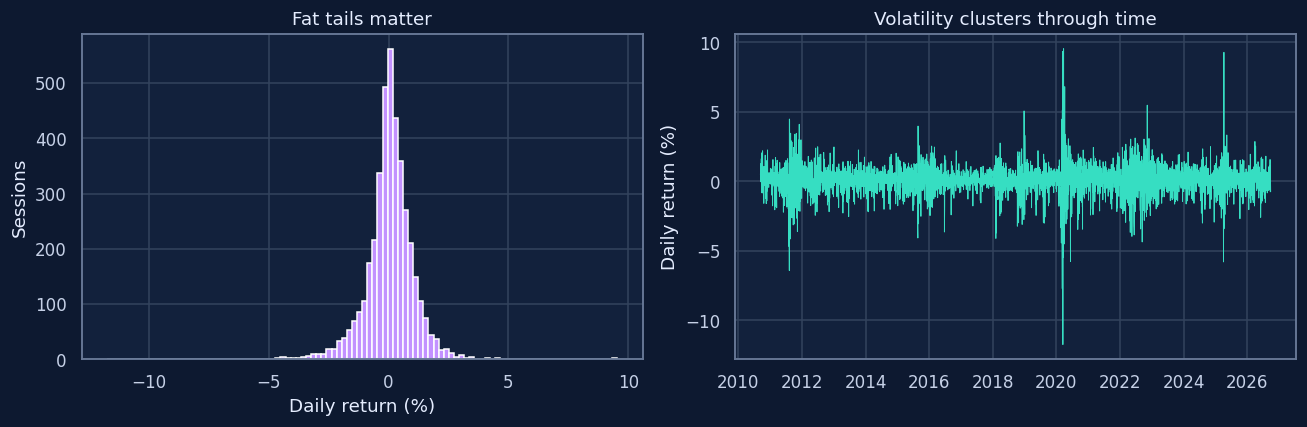

,date,close,return,volume
0,2020-03-16,198.989883,-0.117388,17271500
1,2020-03-12,206.191315,-0.096717,24669300
2,2020-03-09,228.452820,-0.077163,16425900
3,2011-08-08,78.688293,-0.064128,790300
4,2025-04-04,457.493683,-0.057957,30966500
5,2020-03-17,212.017960,0.065471,15115500
6,2020-04-06,221.713913,0.068020,7624000
7,2025-04-09,490.494690,0.092744,29286600
8,2020-03-13,225.455750,0.093430,19533600
9,2020-03-24,203.705856,0.095364,13160800


In [5]:
r=e['return'].dropna()
tail_q=r.quantile(.05)
risk=pd.Series({'Daily mean (%)':r.mean()*100,'Daily median (%)':r.median()*100,
    'Daily standard deviation (%)':r.std()*100,'Skewness':r.skew(),'Excess kurtosis':r.kurt(),
    'Historical daily 5th percentile (%)':tail_q*100,
    'Mean return below 5th percentile (%)':r[r<=tail_q].mean()*100,
    'Positive sessions (%)':(r>0).mean()*100,'Worst session (%)':r.min()*100,'Best session (%)':r.max()*100})
display(risk.round(3).to_frame('Value'))
fig=px.histogram(e,x=e['return']*100,nbins=130,color_discrete_sequence=[COLORS[2]],
                 title='Daily return distribution | Look beyond the average',labels={'x':'Daily return (%)'})
fig.update_layout(height=420)
show_plot(fig,'03_returns')
f,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(r*100,bins=100,color=COLORS[2]);ax[0].set(xlabel='Daily return (%)',ylabel='Sessions',title='Fat tails matter')
ax[1].plot(e.date,e['return']*100,color=COLORS[0],lw=.6);ax[1].set(ylabel='Daily return (%)',title='Volatility clusters through time')
static_done(f,'03_returns')
extremes=pd.concat([e.nsmallest(5,'return'),e.nlargest(5,'return')])[['date','close','return','volume']]
display(extremes.sort_values('return').reset_index(drop=True))

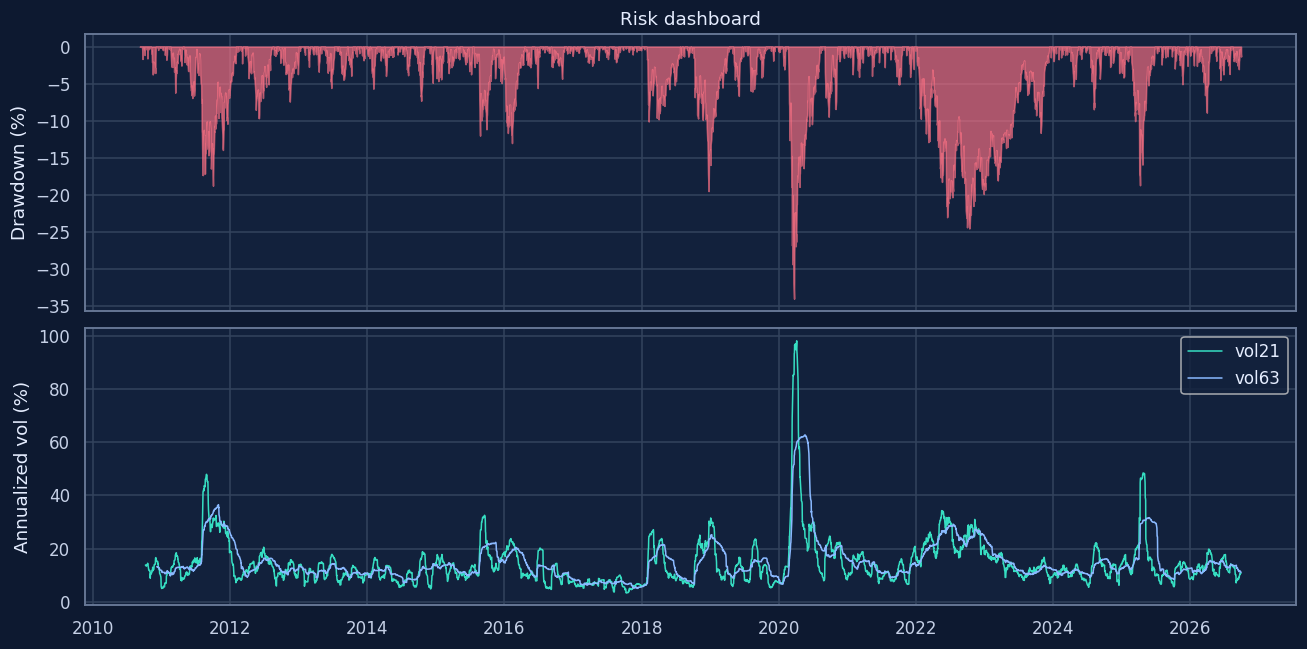

In [6]:
fig=make_subplots(rows=2,cols=1,shared_xaxes=True,vertical_spacing=.13)
fig.add_trace(go.Scatter(x=e.date,y=e.drawdown*100,fill='tozeroy',line_color=COLORS[4],name='Drawdown'),row=1,col=1)
for col in ['vol21','vol63']:
    fig.add_trace(go.Scatter(x=e.date,y=e[col]*100,name=col),row=2,col=1)
fig.update_layout(title='Risk dashboard | Underwater periods and volatility',height=620)
fig.update_yaxes(title_text='Drawdown (%)',row=1,col=1);fig.update_yaxes(title_text='Annualized vol (%)',row=2,col=1)
show_plot(fig,'04_risk')
f,ax=plt.subplots(2,1,figsize=(12,6),sharex=True)
ax[0].fill_between(e.date,e.drawdown*100,0,color=COLORS[4],alpha=.65);ax[0].set_ylabel('Drawdown (%)')
for col in ['vol21','vol63']: ax[1].plot(e.date,e[col]*100,label=col,lw=1)
ax[1].legend();ax[1].set_ylabel('Annualized vol (%)');ax[0].set_title('Risk dashboard')
static_done(f,'04_risk')
trough=int(e.drawdown.idxmin());peak=int(e.close.iloc[:trough+1].idxmax())
recoveries=e.iloc[trough+1:][e.close.iloc[trough+1:]>=e.close.iloc[peak]]
recovery='Not recovered by snapshot end' if recoveries.empty else str(recoveries.date.iloc[0].date())
note('Worst historical drawdown',f'Peak: {e.date.iloc[peak].date()} · Trough: {e.date.iloc[trough].date()} · Decline: {e.drawdown.iloc[trough]:.2%} · First recovery: {recovery}.')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">05</b><h2 style="margin:8px 0;color:#eef5ff">Calendar patterns without overclaiming</h2></div>

Monthly returns use the final available close each month and the preceding month-end close. The first incomplete month is excluded; the latest month is explicitly partial. Annual 2010 data are partial and 2026 is year-to-date. Weekday differences are descriptive and are not proof of a repeatable trading edge; many comparisons invite false discoveries.

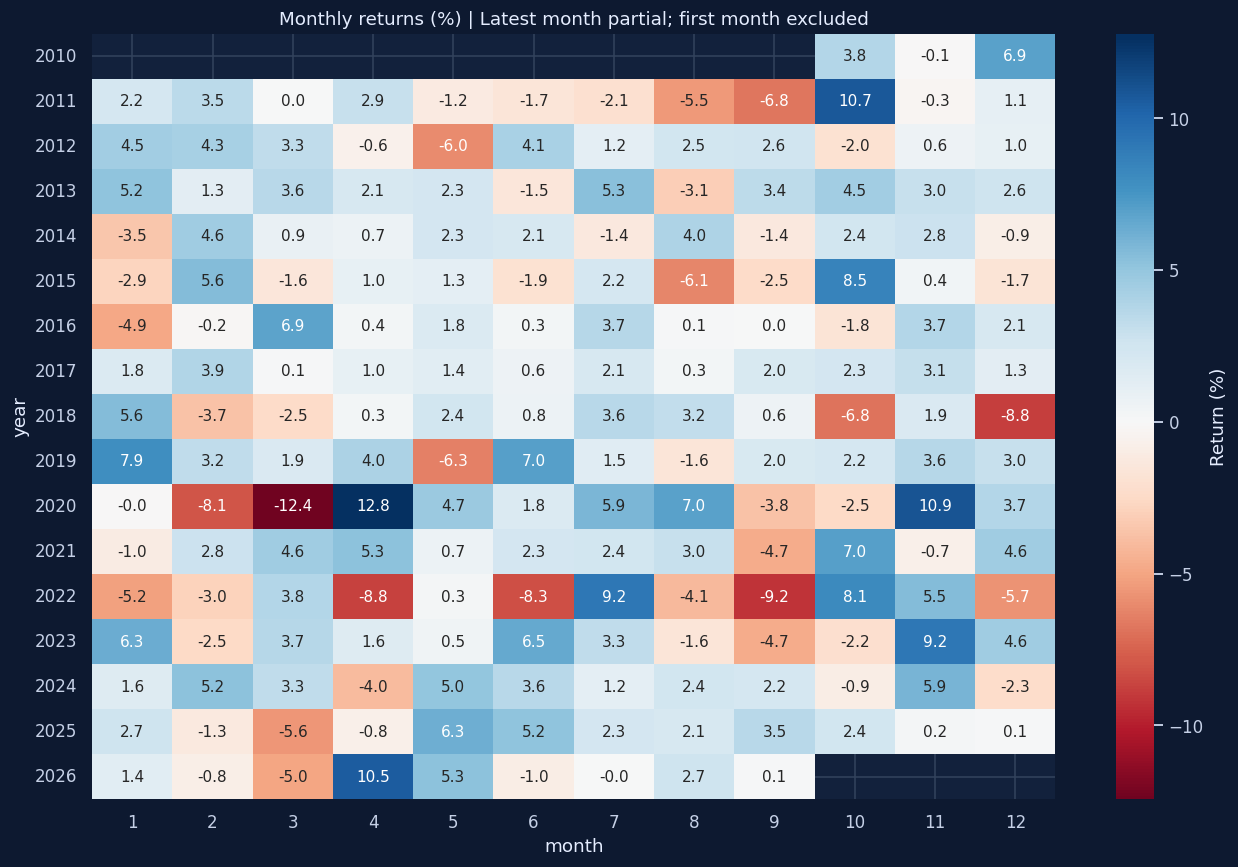

,series_return,period_status
date,,
2010,0.147802,Partial (inception)
2011,0.018974,Full year
2012,0.159928,Full year
2013,0.323865,Full year
2014,0.129279,Full year
2015,0.013251,Full year
2016,0.121667,Full year
2017,0.217736,Full year
2018,-0.045007,Full year


,count,mean_pct
weekday,,
Monday,757,0.050876
Tuesday,830,0.084092
Wednesday,827,0.070893
Thursday,812,0.040468
Friday,810,0.056495


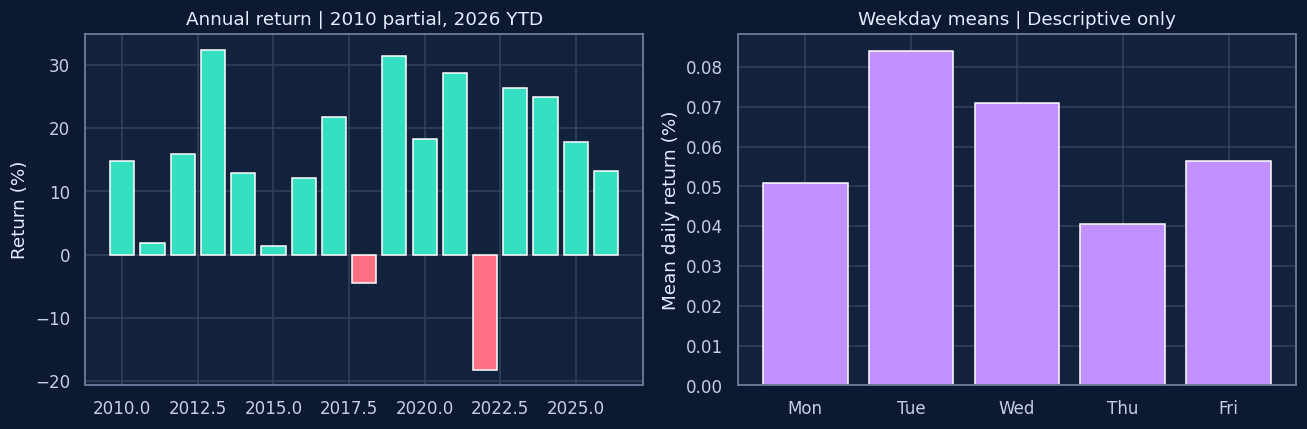

In [7]:
month_close=e.set_index('date').close.resample('ME').last()
monthly=month_close.pct_change(fill_method=None).dropna().rename('return').to_frame()
monthly['year']=monthly.index.year;monthly['month']=monthly.index.month
heat=monthly.pivot(index='year',columns='month',values='return').reindex(columns=range(1,13))*100
fig=px.imshow(heat,aspect='auto',color_continuous_scale='RdBu',color_continuous_midpoint=0,
              title='Monthly returns (%) | September 2026 is partial',labels={'x':'Month','y':'Year','color':'Return %'})
fig.update_layout(height=650)
show_plot(fig,'05_monthly_heatmap')
f,ax=plt.subplots(figsize=(12,8));sns.heatmap(heat,mask=heat.isna(),annot=True,fmt='.1f',cmap='RdBu',center=0,ax=ax,cbar_kws={'label':'Return (%)'})
ax.set_title('Monthly returns (%) | Latest month partial; first month excluded')
static_done(f,'05_monthly_heatmap')
annual=e.groupby(e.date.dt.year)['return'].apply(lambda x:(1+x.dropna()).prod()-1).to_frame('series_return')
annual['period_status']=['Partial (inception)' if y==e.date.dt.year.min() else 'YTD' if y==2026 else 'Full year' for y in annual.index]
display(annual)
week=e.dropna(subset=['return']).copy();week['weekday']=week.date.dt.day_name()
weekday=week.groupby('weekday')['return'].agg(['count','mean','std']).reindex(['Monday','Tuesday','Wednesday','Thursday','Friday'])
weekday['mean_pct']=weekday['mean']*100
display(weekday[['count','mean_pct']])
f,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].bar(annual.index,annual.series_return*100,color=[COLORS[0] if x>=0 else COLORS[4] for x in annual.series_return]);ax[0].set(title='Annual return | 2010 partial, 2026 YTD',ylabel='Return (%)')
ax[1].bar(weekday.index.str[:3],weekday.mean_pct,color=COLORS[2]);ax[1].set(title='Weekday means | Descriptive only',ylabel='Mean daily return (%)')
static_done(f,'06_calendar_patterns')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">06</b><h2 style="margin:8px 0;color:#eef5ff">Dependence, stationarity and trading activity</h2></div>

Price levels often trend while returns are much less persistent. The augmented Dickey–Fuller test has a unit-root null hypothesis; rejection does not imply returns are predictable. Autocorrelation of absolute returns describes volatility persistence. Correlation is descriptive and does not establish causality.

<ipython-input-8-b63b537b8246>:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a=adfuller(s,maxlag=20,autolag='AIC')
<ipython-input-8-b63b537b8246>:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a=adfuller(s,maxlag=20,autolag='AIC')


,series,ADF statistic,p-value,lags
0,Log close,-0.302666,0.925126,9
1,Log return,-21.321975,0.000000,8


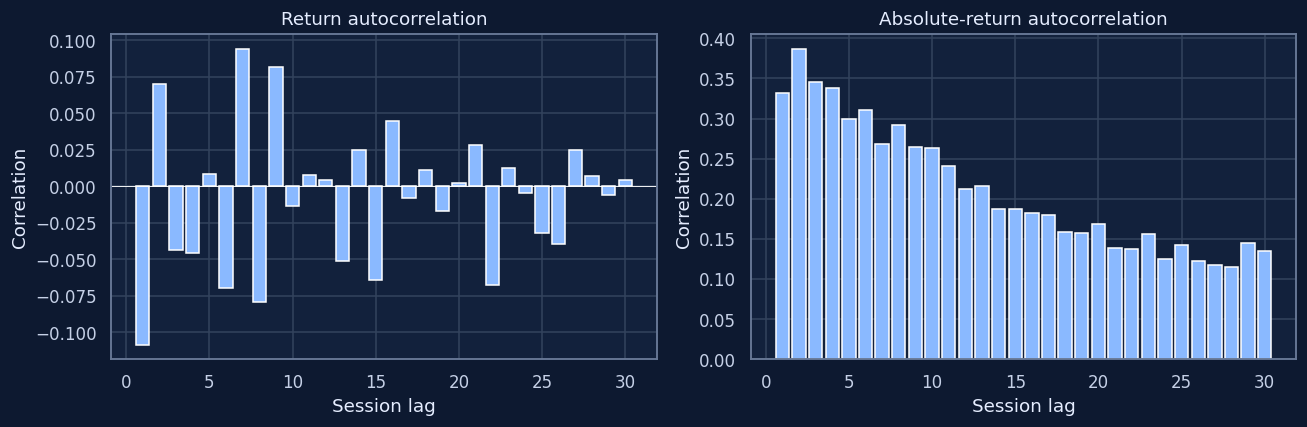

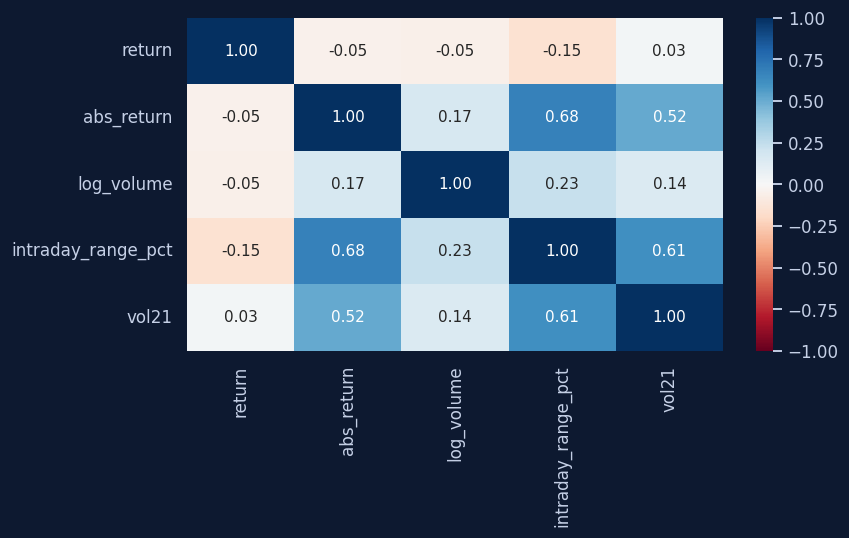

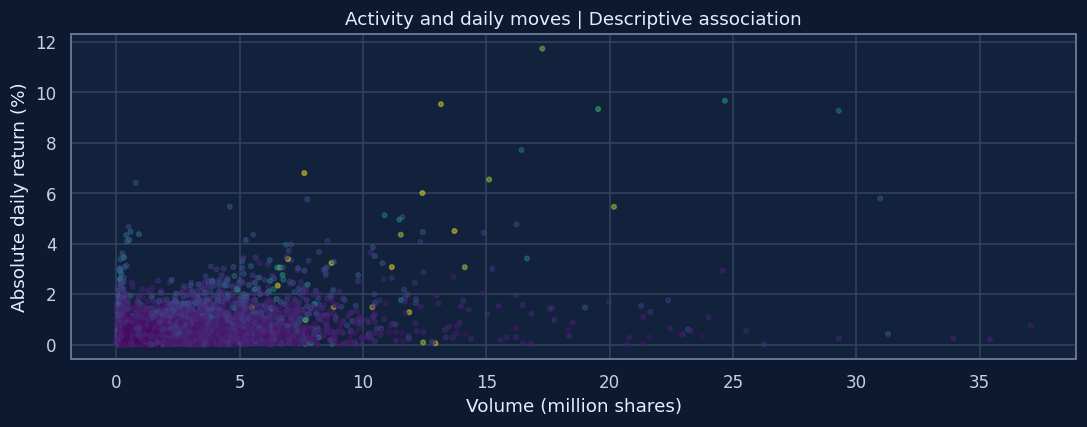

In [8]:
tests=[]
for label,s in [('Log close',np.log(e.close)),('Log return',e.log_return.dropna())]:
    a=adfuller(s,maxlag=20,autolag='AIC')
    tests.append({'series':label,'ADF statistic':a[0],'p-value':a[1],'lags':a[2]})
display(pd.DataFrame(tests))
lags=np.arange(1,31)
acf_r=acf(e.log_return.dropna(),nlags=30,fft=True)[1:]
acf_abs=acf(e.log_return.dropna().abs(),nlags=30,fft=True)[1:]
f,ax=plt.subplots(1,2,figsize=(12,4))
for a,v,title in [(ax[0],acf_r,'Return autocorrelation'),(ax[1],acf_abs,'Absolute-return autocorrelation')]:
    a.bar(lags,v,color=COLORS[1]);a.axhline(0,color='white',lw=.6);a.set(title=title,xlabel='Session lag',ylabel='Correlation')
static_done(f,'07_dependence')
corr_data=pd.DataFrame({'return':e['return'],'abs_return':e['return'].abs(),
    'log_volume':np.log1p(e.volume),'intraday_range_pct':e.range_pct,'vol21':e.vol21})
corr=corr_data.corr()
fig=px.imshow(corr,text_auto='.2f',color_continuous_scale='RdBu',zmin=-1,zmax=1,title='Correlation | Returns, risk and activity')
show_plot(fig,'08_correlations')
f,ax=plt.subplots(figsize=(8,5));sns.heatmap(corr,annot=True,fmt='.2f',cmap='RdBu',vmin=-1,vmax=1,ax=ax)
static_done(f,'08_correlations')
fig=px.scatter(e,x='volume',y=e['return'].abs()*100,color='vol21',opacity=.35,
    title='Trading activity and absolute daily moves',labels={'y':'Absolute daily return (%)','volume':'Shares traded','vol21':'21-session volatility'})
show_plot(fig,'09_activity')
f,ax=plt.subplots(figsize=(10,4));ax.scatter(e.volume/1e6,e['return'].abs()*100,c=e.vol21,cmap='viridis',s=9,alpha=.45)
ax.set(xlabel='Volume (million shares)',ylabel='Absolute daily return (%)',title='Activity and daily moves | Descriptive association')
static_done(f,'09_activity')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">07</b><h2 style="margin:8px 0;color:#eef5ff">Features available at the forecast origin</h2></div>

We forecast **after the close at origin t**. Features may use that session’s OHLCV and prior sessions, but no future values. Targets are cumulative future log changes, `log(close[t+h] / close[t])`, for every horizon h. Multi-output models predict the entire path directly; they never invent future volume or feed actual future prices back into the forecast. Scaling is learned inside each training fold.

In [9]:
future_dates=calendar.sessions_in_range(e.date.iloc[-1]+pd.Timedelta(days=1),'2026-12-31').tz_localize(None)
H=len(future_dates)
assert H>0 and e.date.iloc[-1].year==2026
close=e.close.to_numpy();logp=np.log(close);N=len(e)
X=pd.DataFrame(index=e.index)
for lag in [0,1,2,3,4,9,20]: X[f'log_return_lag_{lag}']=e.log_return.shift(lag)
for w in [5,10,21,63,126,252]:
    X[f'momentum_{w}']=np.log(e.close/e.close.shift(w))
    X[f'volatility_{w}']=e.log_return.rolling(w).std()
    X[f'price_to_ma_{w}']=e.close/e.close.rolling(w).mean()-1
X['intraday_range']=(e.high-e.low)/e.close
X['intraday_change']=np.log(e.close/e.open)
X['overnight_gap']=np.log(e.open/e.close.shift(1))
X['volume_ratio_21']=e.volume/e.volume.rolling(21).mean()
X['drawdown_252']=e.close/e.close.rolling(252).max()-1
X['weekday_sin']=np.sin(2*np.pi*e.date.dt.dayofweek/5)
X['weekday_cos']=np.cos(2*np.pi*e.date.dt.dayofweek/5)
Y=pd.DataFrame({h:np.log(e.close.shift(-h)/e.close) for h in range(1,H+1)})
valid_features=np.isfinite(X).all(axis=1).to_numpy()
valid_targets=np.isfinite(Y).all(axis=1).to_numpy()
feature_dictionary=pd.DataFrame({'feature':X.columns})
feature_dictionary.to_csv(OUTPUT/'model_features.csv',index=False)
note('Forecast horizon',f'{H} scheduled trading sessions: {future_dates[0].date()} through {future_dates[-1].date()}. Thanksgiving and Christmas are excluded; early-close sessions are retained.')
display(X.loc[valid_features].head(3))

,log_return_lag_0,log_return_lag_1,log_return_lag_2,log_return_lag_3,log_return_lag_4,log_return_lag_9,log_return_lag_20,momentum_5,volatility_5,price_to_ma_5,momentum_10,volatility_10,price_to_ma_10,momentum_21,volatility_21,price_to_ma_21,momentum_63,volatility_63,price_to_ma_63,momentum_126,volatility_126,price_to_ma_126,momentum_252,volatility_252,price_to_ma_252,intraday_range,intraday_change,overnight_gap,volume_ratio_21,drawdown_252,weekday_sin,weekday_cos
252,-0.010600,0.027833,-0.006892,-0.026199,-0.009718,-0.015114,-0.044385,-0.025575,0.019903,0.000147,0.007931,0.018140,-0.003205,0.014061,0.023267,0.009592,-0.078313,0.019417,-0.050990,-0.078905,0.014682,-0.074113,0.091078,0.011752,-0.049787,0.017454,-0.004400,-0.006200,0.353222,-0.123485,-0.587785,-0.809017
253,-0.026623,-0.010600,0.027833,-0.006892,-0.026199,0.013074,0.042893,-0.042481,0.022186,-0.017827,-0.003579,0.019570,-0.029055,0.031822,0.021825,-0.018371,-0.090805,0.019614,-0.074632,-0.112234,0.014848,-0.097672,0.059925,0.011871,-0.074948,0.023585,-0.015539,-0.011084,0.550370,-0.146513,-0.951057,0.309017
254,0.007144,-0.026623,-0.010600,0.027833,-0.006892,0.028717,0.007992,-0.009137,0.020480,-0.008986,-0.009509,0.019205,-0.021179,-0.003926,0.019730,-0.011150,-0.084347,0.019642,-0.066783,-0.099225,0.014858,-0.090518,0.054572,0.011854,-0.068499,0.022480,0.019484,-0.012340,0.575384,-0.140394,0.000000,1.000000


<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">08</b><h2 style="margin:8px 0;color:#eef5ff">Select the model before opening the test set</h2></div>

Five candidates compete: last-close, trailing-252-session log drift, standardized Ridge, Random Forest and Extra Trees. Four expanding-history folds each forecast the same H-session horizon from one fixed origin. Training labels must end on or before that origin: **training origin + H ≤ forecast origin**. The final H observed sessions are a separate test. Choose the lowest mean validation MAE divided by origin price (NMAE); do not reselect after reading test results. Hyperparameters below are fixed in advance, not tuned on the test. “Best” means best in this experiment, not universally best.

Validation fold 1/4 complete
Validation fold 2/4 complete
Validation fold 3/4 complete
Validation fold 4/4 complete


,fold,origin,target_start,target_end,last_allowed_training_origin
0,CV 1,2025-06-04,2025-06-05,2025-09-09,2025-02-28
1,CV 2,2025-09-09,2025-09-10,2025-12-11,2025-06-04
2,CV 3,2025-12-11,2025-12-12,2026-03-19,2025-09-09
3,CV 4,2026-03-19,2026-03-20,2026-06-24,2025-12-11
4,Untouched test,2026-06-24,2026-06-25,2026-09-28,2026-03-19


,mean_NMAE_pct,std_NMAE_pct,mean_MAE_USD,mean_RMSE_USD
model,,,,
Ridge,3.5475,1.1389,21.0284,24.2677
Log drift (252),3.5648,2.4130,20.9644,24.1672
Random Forest,4.2241,1.8390,24.5059,27.6887
Extra Trees,4.2433,1.9642,24.5525,27.6963
Last close,4.7487,3.4257,27.6552,31.4250


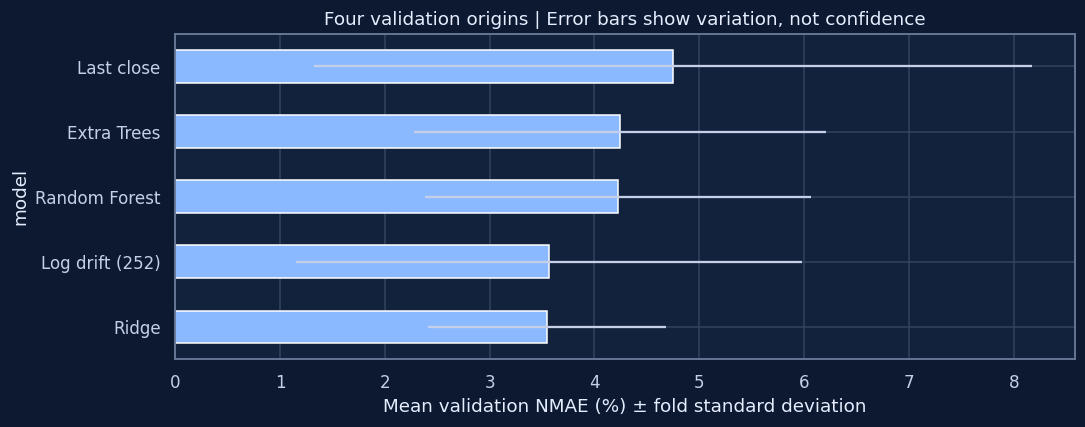

In [10]:
MODEL_NAMES=['Last close','Log drift (252)','Ridge','Random Forest','Extra Trees']
def make_model(name):
    if name=='Ridge': return make_pipeline(StandardScaler(),Ridge(alpha=100.0))
    if name=='Random Forest': return RandomForestRegressor(n_estimators=140,max_depth=8,min_samples_leaf=15,max_features=.8,n_jobs=2,random_state=SEED)
    if name=='Extra Trees': return ExtraTreesRegressor(n_estimators=180,max_depth=10,min_samples_leaf=12,max_features=.9,n_jobs=2,random_state=SEED)
    raise ValueError(name)

def fit_path(name,origin):
    if name=='Last close': return np.repeat(close[origin],H),None
    if name=='Log drift (252)':
        mu=np.diff(logp[max(0,origin-252):origin+1]).mean()
        return close[origin]*np.exp(mu*np.arange(1,H+1)),None
    train_idx=np.flatnonzero(valid_features & valid_targets & (np.arange(N)+H<=origin))
    assert len(train_idx)>500 and train_idx.max()+H<=origin
    model=make_model(name)
    model.fit(X.iloc[train_idx],Y.iloc[train_idx])
    predicted_log=model.predict(X.iloc[[origin]])[0]
    path=close[origin]*np.exp(predicted_log)
    assert np.isfinite(path).all() and (path>0).all()
    return path,model

def score_path(actual,pred,origin):
    naive=np.repeat(close[origin],len(actual))
    mae=mean_absolute_error(actual,pred)
    base=mean_absolute_error(actual,naive)
    scale=np.mean(np.abs(np.diff(close[:origin+1])))
    return {'MAE_USD':float(mae),'RMSE_USD':float(np.sqrt(mean_squared_error(actual,pred))),
        'MAPE_pct':float(np.mean(np.abs((actual-pred)/actual))*100),
        'NMAE_pct':float(mae/close[origin]*100),'MASE_daily_scale':float(mae/scale),
        'R2':float(r2_score(actual,pred)),
        'skill_vs_last_close_pct':float((1-mae/base)*100) if base else np.nan,
        'origin_direction_accuracy_pct':float(np.mean(np.sign(actual-close[origin])==np.sign(pred-close[origin]))*100)}

test_origin=N-H-1
cv_origins=[test_origin-k*H for k in [4,3,2,1]]
assert max(cv_origins)+H==test_origin
split_rows=[];cv_rows=[];cv_predictions=[]
for fold,origin in enumerate(cv_origins,1):
    split_rows.append({'fold':f'CV {fold}','origin':str(e.date.iloc[origin].date()),
        'target_start':str(e.date.iloc[origin+1].date()),'target_end':str(e.date.iloc[origin+H].date()),
        'last_allowed_training_origin':str(e.date.iloc[origin-H].date())})
    actual=close[origin+1:origin+H+1]
    for name in MODEL_NAMES:
        pred,_=fit_path(name,origin)
        cv_rows.append({'fold':fold,'model':name,**score_path(actual,pred,origin)})
        cv_predictions.extend({'fold':fold,'model':name,'horizon':h+1,'date':str(e.date.iloc[origin+h+1].date()),'actual':float(actual[h]),'prediction':float(pred[h])} for h in range(H))
    print(f'Validation fold {fold}/4 complete')
split_rows.append({'fold':'Untouched test','origin':str(e.date.iloc[test_origin].date()),
    'target_start':str(e.date.iloc[test_origin+1].date()),'target_end':str(e.date.iloc[-1].date()),
    'last_allowed_training_origin':str(e.date.iloc[test_origin-H].date())})
splits=pd.DataFrame(split_rows)
cv=pd.DataFrame(cv_rows)
leaderboard=cv.groupby('model').agg(mean_NMAE_pct=('NMAE_pct','mean'),std_NMAE_pct=('NMAE_pct','std'),mean_MAE_USD=('MAE_USD','mean'),mean_RMSE_USD=('RMSE_USD','mean')).sort_values('mean_NMAE_pct')
winner=leaderboard.index[0]
best_ml=leaderboard.loc[['Ridge','Random Forest','Extra Trees']].sort_values('mean_NMAE_pct').index[0]
display(splits);display(leaderboard.round(4))
note('Model selection locked',f'Validation winner: <b>{winner}</b>. Best ML candidate: <b>{best_ml}</b>. The test will assess these frozen choices.')
cv.to_csv(OUTPUT/'validation_metrics.csv',index=False)
leaderboard.to_csv(OUTPUT/'validation_leaderboard.csv')
pd.DataFrame(cv_predictions).to_csv(OUTPUT/'validation_predictions.csv',index=False)
splits.to_csv(OUTPUT/'split_dates.csv',index=False)
fig=px.bar(cv,x='model',y='NMAE_pct',color='fold',barmode='group',title='Fixed-origin validation | Lower error is better',labels={'NMAE_pct':'MAE / origin price (%)'})
show_plot(fig,'10_validation')
f,ax=plt.subplots(figsize=(10,4));leaderboard.mean_NMAE_pct.plot.barh(ax=ax,color=COLORS[1],xerr=leaderboard.std_NMAE_pct)
ax.set(xlabel='Mean validation NMAE (%) ± fold standard deviation',title='Four validation origins | Error bars show variation, not confidence')
static_done(f,'10_validation')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">09</b><h2 style="margin:8px 0;color:#eef5ff">The untouched test: did the advantage survive?</h2></div>

MAE and RMSE are dollar errors across one full fixed-origin path. MAPE and NMAE express relative error. Positive skill means lower MAE than the last-close path. MASE uses the mean in-sample one-day absolute change as its scale; it is not a same-horizon baseline ratio. R² can be negative and is not trading accuracy. Origin-direction accuracy compares each endpoint with the starting close; it is not next-day hit rate. Horizon endpoints are dependent, so these are not H independent experiments.

,selected_before_test,MAE_USD,RMSE_USD,MAPE_pct,NMAE_pct,MASE_daily_scale,R2,skill_vs_last_close_pct,origin_direction_accuracy_pct
model,,,,,,,,,
Last close,False,23.5490,26.1474,3.3599,3.5043,12.5271,-3.9385,0.0000,0.0000
Log drift (252),False,8.0997,9.7255,1.1617,1.2053,4.3087,0.3168,65.6050,96.9697
Ridge,True,16.2880,18.6226,2.3258,2.4238,8.6646,-1.5051,30.8333,86.3636
Random Forest,False,15.8717,18.0930,2.2639,2.3619,8.4431,-1.3646,32.6011,96.9697
Extra Trees,False,15.4447,17.8496,2.2025,2.2983,8.2159,-1.3014,34.4144,96.9697


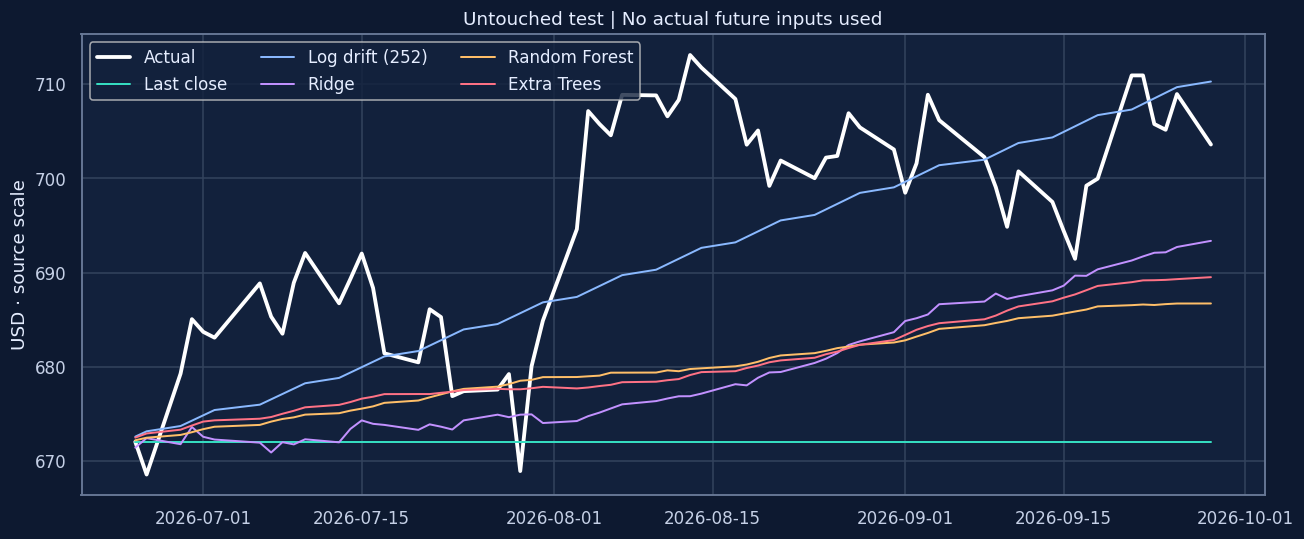

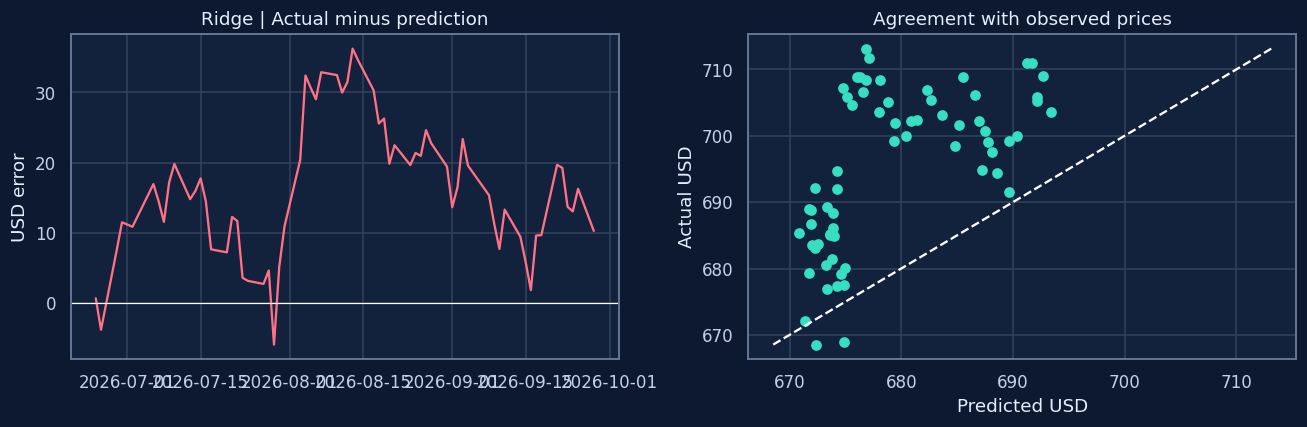

In [11]:
actual_test=close[test_origin+1:]
test_dates=e.date.iloc[test_origin+1:]
test_paths={};test_models={};test_rows=[]
for name in MODEL_NAMES:
    pred,model=fit_path(name,test_origin)
    test_paths[name]=pred;test_models[name]=model
    test_rows.append({'model':name,'selected_before_test':name==winner,**score_path(actual_test,pred,test_origin)})
test_metrics=pd.DataFrame(test_rows).set_index('model')
display(test_metrics.round(4))
test_metrics.to_csv(OUTPUT/'test_metrics.csv')
test_export=pd.DataFrame({'date':test_dates.to_numpy(),'actual':actual_test,**test_paths})
test_export.to_csv(OUTPUT/'test_predictions.csv',index=False)
fig=go.Figure(go.Scatter(x=test_dates,y=actual_test,name='Actual',line=dict(color='white',width=3)))
for name in MODEL_NAMES: fig.add_trace(go.Scatter(x=test_dates,y=test_paths[name],name=name))
fig.update_layout(title=f'Untouched {H}-session test | All paths issued at {e.date.iloc[test_origin].date()}',yaxis_title='USD · source scale',height=530)
show_plot(fig,'11_test_paths')
f,ax=plt.subplots(figsize=(12,5));ax.plot(test_dates,actual_test,label='Actual',color='white',lw=2.5)
for name in MODEL_NAMES: ax.plot(test_dates,test_paths[name],label=name,lw=1.3)
ax.legend(ncol=3);ax.set(title='Untouched test | No actual future inputs used',ylabel='USD · source scale')
static_done(f,'11_test_paths')
residual=actual_test-test_paths[winner]
f,ax=plt.subplots(1,2,figsize=(12,4));ax[0].plot(test_dates,residual,color=COLORS[4]);ax[0].axhline(0,color='white',lw=.8)
ax[0].set(title=f'{winner} | Actual minus prediction',ylabel='USD error');ax[1].scatter(test_paths[winner],actual_test,color=COLORS[0])
limits=[min(actual_test.min(),test_paths[winner].min()),max(actual_test.max(),test_paths[winner].max())]
ax[1].plot(limits,limits,color='white',ls='--');ax[1].set(xlabel='Predicted USD',ylabel='Actual USD',title='Agreement with observed prices')
static_done(f,'12_test_errors')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">10</b><h2 style="margin:8px 0;color:#eef5ff">What did the strongest tree model use?</h2></div>

Feature importance is a model diagnostic, not a causal explanation or proof of predictive value. This chart uses the better tree model on validation, fitted only through the test origin. Impurity importance can distribute weight unpredictably across correlated features and is biased toward features with more split opportunities. No feature is dropped or model retuned after the test.

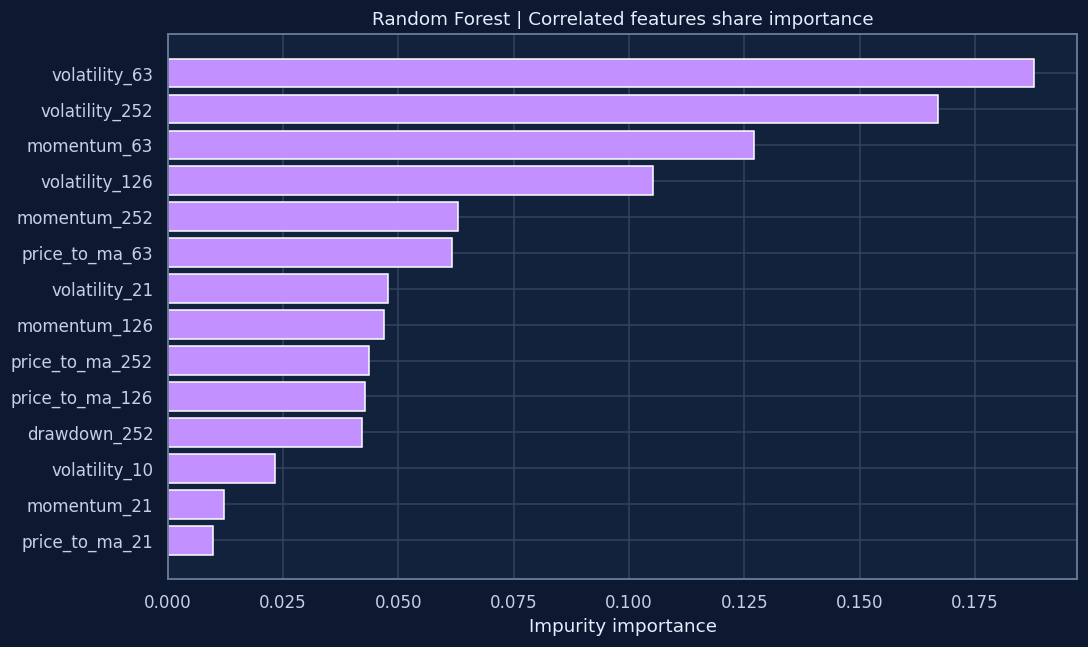

In [12]:
tree_name=leaderboard.loc[['Random Forest','Extra Trees']].sort_values('mean_NMAE_pct').index[0]
importance=pd.Series(test_models[tree_name].feature_importances_,index=X.columns).sort_values(ascending=False)
importance.rename('impurity_importance').to_csv(OUTPUT/'feature_importance.csv')
top=importance.head(14).sort_values()
fig=px.bar(x=top.values,y=top.index,orientation='h',title=f'{tree_name} | Diagnostic feature importance',labels={'x':'Impurity importance','y':'Feature'})
show_plot(fig,'13_importance')
f,ax=plt.subplots(figsize=(10,6));ax.barh(top.index,top.values,color=COLORS[2]);ax.set(xlabel='Impurity importance',title=f'{tree_name} | Correlated features share importance')
static_done(f,'13_importance')

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">11</b><h2 style="margin:8px 0;color:#eef5ff">Remaining 2026 sessions: a path and its uncertainty</h2></div>

Refit the validation-selected model using all labels observable at the last supplied close. Also show the best ML path and last-close baseline. Uncertainty comes from 5-session blocks of centered historical log returns from the preceding 1,260 sessions, accumulated around the selected path. The central 80% and 95% **simulation bands are scenarios, not calibrated prediction intervals**. They omit model, drift and regime uncertainty and may understate risk. Coverage on one historical test path is only a descriptive check.

<ipython-input-13-82aac603d5be>:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(month_ends[['date','forecast_close','scenario_lower_80','scenario_upper_80','best_ml_forecast_close']].round(2))


,nominal_simulation_band,test_path_coverage_pct
0,80%,100.0
1,95%,100.0


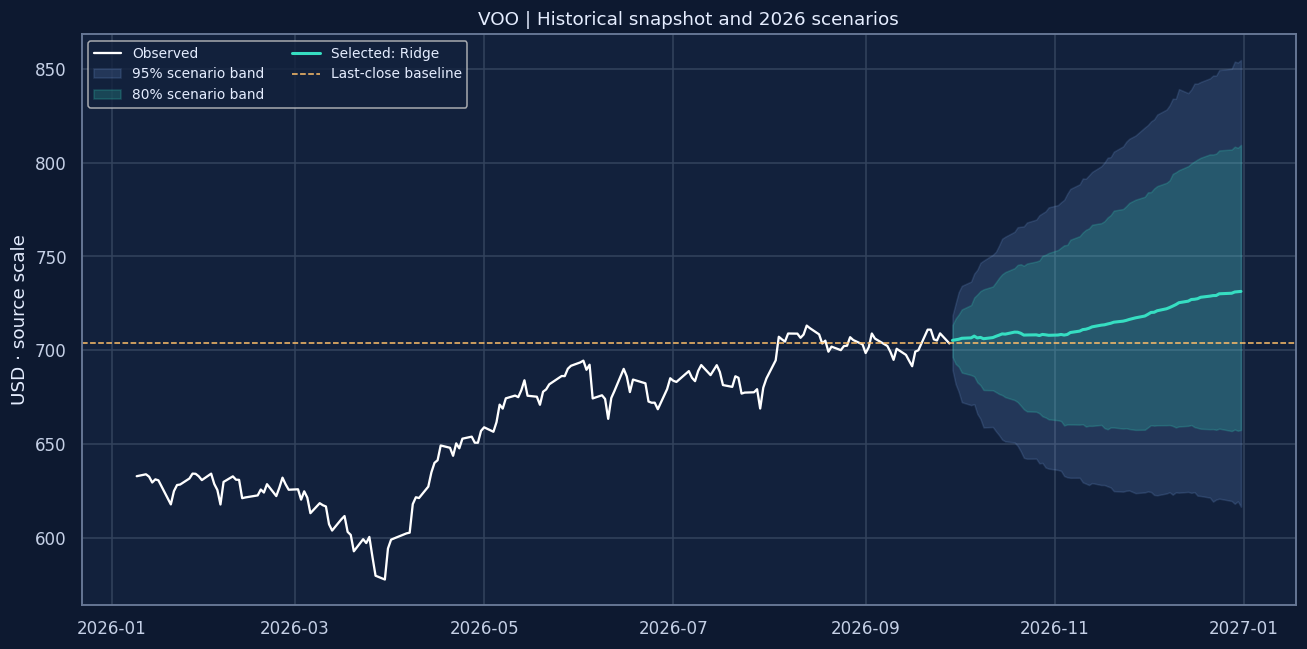

,date,forecast_close,scenario_lower_80,scenario_upper_80,best_ml_forecast_close
1,2026-09-30,705.55,692.74,716.8,705.55
23,2026-10-30,707.95,663.16,751.8,707.95
43,2026-11-30,718.22,657.62,781.8,718.22
65,2026-12-31,731.34,657.48,809.4,731.34


In [13]:
def scenario_bands(path,origin,seed=SEED,simulations=5000,block=5):
    rng=np.random.default_rng(seed)
    innovations=np.diff(logp[max(0,origin-1260):origin+1])
    innovations=innovations-innovations.mean()
    starts=rng.integers(0,len(innovations)-block+1,size=(simulations,math.ceil(len(path)/block)))
    shocks=innovations[starts[:,:,None]+np.arange(block)].reshape(simulations,-1)[:,:len(path)]
    sims=np.asarray(path)[None,:]*np.exp(np.cumsum(shocks,axis=1))
    return np.quantile(sims,[.025,.10,.90,.975],axis=0)

test_bands=scenario_bands(test_paths[winner],test_origin)
coverage80=float(np.mean((actual_test>=test_bands[1]) & (actual_test<=test_bands[2]))*100)
coverage95=float(np.mean((actual_test>=test_bands[0]) & (actual_test<=test_bands[3]))*100)
display(pd.DataFrame({'nominal_simulation_band':['80%','95%'],'test_path_coverage_pct':[coverage80,coverage95]}))
final_path,final_model=fit_path(winner,N-1)
ml_path,final_ml_model=fit_path(best_ml,N-1)
bands=scenario_bands(final_path,N-1)
forecast=pd.DataFrame({'date':future_dates,'ticker':'VOO','horizon_sessions':np.arange(1,H+1),
    'selected_model':winner,'forecast_close':final_path,'scenario_lower_80':bands[1],
    'scenario_upper_80':bands[2],'scenario_lower_95':bands[0],'scenario_upper_95':bands[3],
    'best_ml_model':best_ml,'best_ml_forecast_close':ml_path,'last_close_baseline':close[-1]})
assert np.isfinite(forecast.select_dtypes('number')).all().all()
assert ((forecast.scenario_lower_95<=forecast.scenario_lower_80)&(forecast.scenario_lower_80<=forecast.scenario_upper_80)&(forecast.scenario_upper_80<=forecast.scenario_upper_95)).all()
forecast.to_csv(OUTPUT/'voo_forecast_2026.csv',index=False,float_format='%.6f')
fig=go.Figure()
fig.add_trace(go.Scatter(x=e.date.tail(180),y=e.close.tail(180),name='Observed',line=dict(color='white',width=2)))
for lo,hi,label,color in [(bands[0],bands[3],'95% scenario band','rgba(138,185,255,0.13)'),(bands[1],bands[2],'80% scenario band','rgba(54,222,194,0.20)')]:
    fig.add_trace(go.Scatter(x=future_dates,y=lo,line=dict(width=0),showlegend=False))
    fig.add_trace(go.Scatter(x=future_dates,y=hi,fill='tonexty',fillcolor=color,line=dict(width=0),name=label))
fig.add_trace(go.Scatter(x=future_dates,y=final_path,name=f'Selected: {winner}',line=dict(color=COLORS[0],width=3)))
if best_ml!=winner: fig.add_trace(go.Scatter(x=future_dates,y=ml_path,name=f'ML comparison: {best_ml}',line=dict(color=COLORS[2],dash='dot')))
fig.add_trace(go.Scatter(x=future_dates,y=np.repeat(close[-1],H),name='Last-close baseline',line=dict(color=COLORS[3],dash='dash')))
fig.update_layout(title='VOO | Remaining 2026 sessions · Scenario bands, not guarantees',height=580,yaxis_title='USD · source scale')
show_plot(fig,'14_forecast')
f,ax=plt.subplots(figsize=(12,6));ax.plot(e.date.tail(180),e.close.tail(180),color='white',label='Observed')
ax.fill_between(future_dates,bands[0],bands[3],color=COLORS[1],alpha=.15,label='95% scenario band')
ax.fill_between(future_dates,bands[1],bands[2],color=COLORS[0],alpha=.2,label='80% scenario band')
ax.plot(future_dates,final_path,color=COLORS[0],lw=2,label=f'Selected: {winner}')
if best_ml!=winner: ax.plot(future_dates,ml_path,color=COLORS[2],ls=':',label=f'ML: {best_ml}')
ax.axhline(close[-1],color=COLORS[3],ls='--',lw=1,label='Last-close baseline')
ax.set(title='VOO | Historical snapshot and 2026 scenarios',ylabel='USD · source scale');ax.legend(ncol=2,fontsize=9)
static_done(f,'14_forecast')
month_ends=forecast.groupby(forecast.date.dt.to_period('M')).tail(1)
display(month_ends[['date','forecast_close','scenario_lower_80','scenario_upper_80','best_ml_forecast_close']].round(2))

<div style="background:#12213c;border-left:6px solid #36dec2;padding:18px;border-radius:10px;color:#eef5ff"><b style="color:#36dec2">12</b><h2 style="margin:8px 0;color:#eef5ff">What the evidence supports</h2></div>

A good research notebook makes its conclusions depend on the results. The report below is generated from this run, including unfavorable test results. A snapshot-based forecast is not a recommendation to buy or sell.

In [14]:
selected_test=test_metrics.loc[winner]
outlook={'selected_model':winner,'best_ml_model':best_ml,'horizon_sessions':H,
    'forecast_start':str(future_dates[0].date()),'forecast_end':str(future_dates[-1].date()),
    'year_end_forecast':float(final_path[-1]),'year_end_change_pct':float((final_path[-1]/close[-1]-1)*100),
    'year_end_scenario_lower_80':float(bands[1,-1]),'year_end_scenario_upper_80':float(bands[2,-1]),
    'test_MAE_USD':float(selected_test.MAE_USD),'test_RMSE_USD':float(selected_test.RMSE_USD),
    'test_MAPE_pct':float(selected_test.MAPE_pct),'test_skill_vs_last_close_pct':float(selected_test.skill_vs_last_close_pct),
    'test_scenario_coverage_80_pct':coverage80,'test_scenario_coverage_95_pct':coverage95}
verdict='outperformed' if selected_test.skill_vs_last_close_pct>0 else 'matched' if abs(selected_test.skill_vs_last_close_pct)<1e-9 else 'underperformed'
report=f'''# VOO research findings

Author: Muhammad Ibrahim Shahrukh

## Historical evidence
- {len(e):,} daily observations, {e.date.iloc[0].date()} through {e.date.iloc[-1].date()}.
- Latest supplied close: ${close[-1]:,.2f}. This is the source scale; adjustment status is unverified.
- Supplied-series annualized growth: {summary['series_cagr_pct']:.2f}%; annualized log-return volatility: {summary['annualized_volatility_pct']:.2f}%.
- Largest peak-to-trough drawdown: {summary['maximum_drawdown_pct']:.2f}%, from {e.date.iloc[peak].date()} to {e.date.iloc[trough].date()}.
- Daily return skewness: {r.skew():.2f}; excess kurtosis: {r.kurt():.2f}. Large shocks make averages an incomplete risk summary.

## Model evidence
- Validation winner: **{winner}**; best machine-learning candidate: **{best_ml}**.
- Four fixed-origin {H}-session validation folds precede one untouched {H}-session test.
- Selected-model test MAE: ${selected_test.MAE_USD:.2f}; RMSE: ${selected_test.RMSE_USD:.2f}; MAPE: {selected_test.MAPE_pct:.2f}%.
- The selected model **{verdict}** last-close on test MAE; skill: {selected_test.skill_vs_last_close_pct:.2f}%.
- The lowest test MAE belongs to **{test_metrics.MAE_USD.idxmin()}** (${test_metrics.MAE_USD.min():.2f}), which may differ from the validation winner. The final model is deliberately not reselected using this test. A weaker result than a trend baseline limits the evidence for a stable machine-learning advantage.
- Test-path scenario coverage: {coverage80:.1f}% for the nominal 80% band and {coverage95:.1f}% for the nominal 95% band. One path does not establish calibration.

## 2026 projection
- {H} scheduled sessions, {future_dates[0].date()}–{future_dates[-1].date()}.
- Selected year-end path value: **${final_path[-1]:,.2f}** ({(final_path[-1]/close[-1]-1)*100:+.2f}% versus the last supplied close).
- Year-end central 80% simulation range: **${bands[1,-1]:,.2f}–${bands[2,-1]:,.2f}**.
- This path describes a fitted statistical scenario. A smooth or rising curve is not evidence that daily prices will behave that way.

## Interpretation and next research steps
Long-run growth coexists with sharp drawdowns. Recent trends can persist, stall or reverse; historical OHLCV alone cannot distinguish those cases reliably. Earnings expectations, interest rates, index composition and market shocks can affect future prices, but none is measured by this model. They are possible drivers, not claims about the current economy.

The test verdict above takes priority over a visually appealing forecast. Four validation origins and one recent test provide limited regime coverage. Overlapping training targets and correlated horizon errors reduce the effective sample size. Expand the origin set across market regimes before drawing strong performance conclusions. Test additional model families and hyperparameters in a new nested validation design, not by repeatedly optimizing this test.

Verify adjustment flags and corporate actions, retain point-in-time snapshots, and add explicitly timestamped exogenous features if available. The present backtest uses one historical export: past adjusted values may have been revised after their original dates. Thus feature/target timing is protected within this snapshot, but full point-in-time data integrity is not established. There is no transaction-cost backtest, no portfolio optimization and no claimed trading edge.

Forecast and historical tables are separate. Scenario bands omit parameter uncertainty and structural breaks. Educational research only; no promised returns.
'''
display(Markdown(report))
(OUTPUT/'research_findings.md').write_text(report)
(OUTPUT/'run_summary.json').write_text(json.dumps({'history':summary,'forecast':outlook,'versions':versions},indent=2))
e.to_csv(OUTPUT/'voo_eda_features.csv',index=False)
note('All exports complete', 'Clean history stays separate from forecasts. Outputs include audit results, validation and test metrics, forecast paths, feature importance, interactive charts, static figures and this evidence-based research report.')

# VOO research findings

Author: Muhammad Ibrahim Shahrukh

## Historical evidence
- 4,037 daily observations, 2010-09-09 through 2026-09-28.
- Latest supplied close: $703.61. This is the source scale; adjustment status is unverified.
- Supplied-series annualized growth: 14.86%; annualized log-return volatility: 17.00%.
- Largest peak-to-trough drawdown: -33.99%, from 2020-02-19 to 2020-03-23.
- Daily return skewness: -0.38; excess kurtosis: 13.59. Large shocks make averages an incomplete risk summary.

## Model evidence
- Validation winner: **Ridge**; best machine-learning candidate: **Ridge**.
- Four fixed-origin 66-session validation folds precede one untouched 66-session test.
- Selected-model test MAE: $16.29; RMSE: $18.62; MAPE: 2.33%.
- The selected model **outperformed** last-close on test MAE; skill: 30.83%.
- The lowest test MAE belongs to **Log drift (252)** ($8.10), which may differ from the validation winner. The final model is deliberately not reselected using this test. A weaker result than a trend baseline limits the evidence for a stable machine-learning advantage.
- Test-path scenario coverage: 100.0% for the nominal 80% band and 100.0% for the nominal 95% band. One path does not establish calibration.

## 2026 projection
- 66 scheduled sessions, 2026-09-29–2026-12-31.
- Selected year-end path value: **$731.34** (+3.94% versus the last supplied close).
- Year-end central 80% simulation range: **$657.48–$809.40**.
- This path describes a fitted statistical scenario. A smooth or rising curve is not evidence that daily prices will behave that way.

## Interpretation and next research steps
Long-run growth coexists with sharp drawdowns. Recent trends can persist, stall or reverse; historical OHLCV alone cannot distinguish those cases reliably. Earnings expectations, interest rates, index composition and market shocks can affect future prices, but none is measured by this model. They are possible drivers, not claims about the current economy.

The test verdict above takes priority over a visually appealing forecast. Four validation origins and one recent test provide limited regime coverage. Overlapping training targets and correlated horizon errors reduce the effective sample size. Expand the origin set across market regimes before drawing strong performance conclusions. Test additional model families and hyperparameters in a new nested validation design, not by repeatedly optimizing this test.

Verify adjustment flags and corporate actions, retain point-in-time snapshots, and add explicitly timestamped exogenous features if available. The present backtest uses one historical export: past adjusted values may have been revised after their original dates. Thus feature/target timing is protected within this snapshot, but full point-in-time data integrity is not established. There is no transaction-cost backtest, no portfolio optimization and no claimed trading edge.

Forecast and historical tables are separate. Scenario bands omit parameter uncertainty and structural breaks. Educational research only; no promised returns.


### Sources, collection and reuse

1. **Underlying provider:** [Yahoo Finance — VOO historical data](https://finance.yahoo.com/quote/VOO/history/). The user attributes the uploaded file to Yahoo Finance via yfinance; no independent price-by-price verification or new collection was performed.
2. **Collection software:** [yfinance project](https://github.com/ranaroussi/yfinance). yfinance is an unofficial open-source interface. The exact original command, software version, download time and adjustment flags were not supplied. The export structure is consistent with a single-ticker, daily multi-index download; that structure cannot prove the original arguments.
3. **Fund identity:** [Vanguard VOO profile](https://investor.vanguard.com/investment-products/etfs/profile/voo).
4. **Calendar:** [NYSE holidays and trading hours](https://www.nyse.com/trade/hours-calendars). XNYS sessions are used as the U.S. equity full-day calendar proxy for NYSE Arca-listed VOO; early closes remain observations. Scheduled 2026 holidays were checked against the official calendar. Unscheduled future closures cannot be predicted.
5. **Methodology:** [scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) and [ensemble models](https://scikit-learn.org/stable/modules/ensemble.html). Training transformations and model selection are separated from the final test.

**Preparation date:** September 29, 2026. **Collection date:** unknown. **Observed range:** September 9, 2010–September 28, 2026.

**Reuse rights:** Attribution alone is not redistribution permission. The yfinance code license does not license Yahoo market data; the project points users to Yahoo's terms and describes personal-use restrictions. No new open-data license is asserted here. Check applicable data rights before publishing the CSV on Kaggle or GitHub.

**Suggested citation:** Muhammad Ibrahim Shahrukh (2026), *VOO ETF Historical Prices & 2026 Forecast*, user-supplied Yahoo Finance/yfinance snapshot through September 28, 2026. Add your public dataset DOI or URL after publication.

<div style="background:#26345a;color:white;padding:22px;border-radius:12px"><b>Continue the research</b><br>Which benchmark is hardest to beat? Does the conclusion survive another market regime? What data would reduce the uncertainty most? Share reproducible improvements and thoughtful feedback.</div>